# 06 · Du risque à la décision : seuil d'octroi et grille de points

Le modèle donne une **probabilité de défaut (PD)**. La banque, elle, doit répondre **oui ou non**.
Ce notebook répond à trois questions :

1. **À partir de quelle PD refuser un crédit ?** (seuil de décision)
2. **Combien la banque y gagne-t-elle ?**
3. **Comment présenter le risque simplement ?** (score en points, classes de risque A à E, grille de points)

In [1]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from credit_risk_scoring import decision as d
from credit_risk_scoring.config import FIGURES
from credit_risk_scoring.lgbm import MODEL_PATH
from credit_risk_scoring.modeling import load_features, split
from credit_risk_scoring.scorecard import MODEL_PATH as SCORECARD_PATH

sns.set_theme(style="whitegrid")
df = load_features()
X_train, X_test, y_train, y_test = split(df)
lgbm = joblib.load(MODEL_PATH)
scorecard = joblib.load(SCORECARD_PATH)

pd_test = lgbm.predict_proba(X_test)
amount = X_test["AMT_CREDIT"].to_numpy()

## 1. Le raisonnement économique

Pour chaque crédit accordé :
- si le client **rembourse**, la banque gagne une **marge** : ici **10 %** du montant (intérêts, moins le coût de l'argent) ;
- si le client fait **défaut**, elle perd une partie du montant : la **LGD** (*Loss Given Default*), ici **60 %**
  (le reste est récupéré par le recouvrement ou les garanties).

Le gain espéré d'un crédit est donc :

$$\text{gain espéré} = (1 - \text{PD}) \times 10\,\% - \text{PD} \times 60\,\%$$

Il est positif tant que :

$$\text{PD} < \frac{10\,\%}{10\,\% + 60\,\%} \approx 14{,}3\,\%$$

**Règle :** on accorde le crédit si la PD est inférieure à 14,3 %.

> ⚠️ Ces deux chiffres sont des **hypothèses illustratives**. Dans une vraie banque, ils viennent de la direction
> financière (marge) et du recouvrement (LGD). Le code permet de les changer facilement.

In [2]:
threshold = d.breakeven_threshold()
print(f"Seuil de rentabilité : PD < {threshold:.1%}")

Seuil de rentabilité : PD < 14.3%


## 2. Vérification sur le test : combien gagne la banque ?

Pour plusieurs seuils, on simule la politique d'octroi sur les 61 503 demandes du test, dont on connaît l'issue réelle.

In [3]:
thresholds = [0.03, 0.05, 0.08, 0.10, 0.12, threshold, 0.16, 0.20, 0.30, 1.0 + 1e-9]   # dernier seuil : tout accepter
table = d.threshold_table(y_test, pd_test, amount, thresholds)
accept_all = d.expected_profit(y_test, pd_test, amount, 1.0 + 1e-9)
table["gain_vs_tout_accepter"] = table["gain"] / accept_all - 1
table.style.format({
    "seuil_PD": "{:.1%}", "taux_acceptation": "{:.1%}", "taux_defaut_acceptes": "{:.1%}",
    "mauvais_payeurs_refuses": "{:.1%}", "bons_payeurs_refuses": "{:.1%}",
    "gain": "{:,.0f}", "gain_vs_tout_accepter": "{:+.1%}",
})

,seuil_PD,taux_acceptation,taux_defaut_acceptes,mauvais_payeurs_refuses,bons_payeurs_refuses,gain,gain_vs_tout_accepter
0,3.0%,33.6%,1.6%,93.1%,64.0%,"1,141,874,771",-34.3%
1,5.0%,52.6%,2.4%,84.2%,44.2%,"1,679,718,796",-3.4%
2,8.0%,68.7%,3.3%,71.5%,27.8%,"2,011,251,709",+15.7%
3,10.0%,75.4%,3.9%,63.9%,21.1%,"2,099,464,888",+20.8%
4,12.0%,80.2%,4.4%,56.5%,16.6%,"2,110,950,292",+21.4%
5,14.3%,84.3%,4.8%,50.2%,12.7%,"2,127,050,149",+22.3%
6,16.0%,86.6%,5.1%,45.4%,10.5%,"2,118,824,944",+21.9%
7,20.0%,90.7%,5.7%,36.2%,6.9%,"2,084,593,446",+19.9%
8,30.0%,96.0%,6.7%,20.2%,2.6%,"1,964,638,587",+13.0%
9,100.0%,100.0%,8.1%,0.0%,0.0%,"1,738,670,587",+0.0%


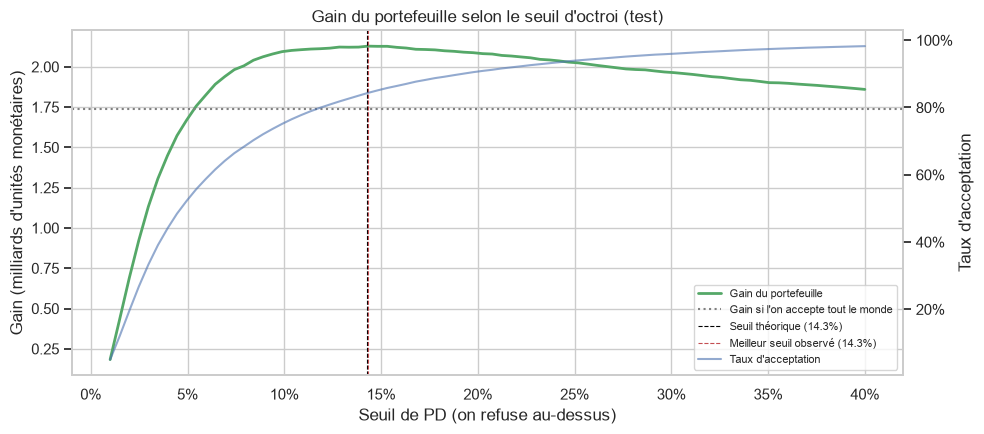

In [4]:
grid = np.linspace(0.01, 0.40, 80)
curve = d.threshold_table(y_test, pd_test, amount, grid)
best = curve.loc[curve["gain"].idxmax()]

fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax1.plot(curve["seuil_PD"], curve["gain"] / 1e9, color="#55A868", lw=2, label="Gain du portefeuille")
ax1.axhline(accept_all / 1e9, color="grey", ls=":", label="Gain si l'on accepte tout le monde")
ax1.axvline(threshold, color="black", ls="--", lw=0.8, label=f"Seuil théorique ({threshold:.1%})")
ax1.axvline(best["seuil_PD"], color="#C44E52", ls="--", lw=0.8, label=f"Meilleur seuil observé ({best['seuil_PD']:.1%})")
ax1.set_xlabel("Seuil de PD (on refuse au-dessus)"); ax1.set_ylabel("Gain (milliards d'unités monétaires)")
ax1.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax2 = ax1.twinx()
ax2.plot(curve["seuil_PD"], curve["taux_acceptation"], color="#4C72B0", alpha=0.6, label="Taux d'acceptation")
ax2.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax2.set_ylabel("Taux d'acceptation"); ax2.grid(False)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="lower right", fontsize=8)
ax1.set_title("Gain du portefeuille selon le seuil d'octroi (test)")
plt.tight_layout(); plt.savefig(FIGURES / "06_seuil_gain.png", dpi=120); plt.show()

In [5]:
policy = table.loc[table["seuil_PD"] == threshold].iloc[0]
print(f"Avec le seuil de {threshold:.1%} :")
print(f"  - {policy['taux_acceptation']:.1%} des demandes acceptées")
print(f"  - {policy['mauvais_payeurs_refuses']:.1%} des mauvais payeurs écartés, pour {policy['bons_payeurs_refuses']:.1%} des bons payeurs refusés")
print(f"  - taux de défaut du portefeuille accepté : {policy['taux_defaut_acceptes']:.1%} (contre {y_test.mean():.1%} sans sélection)")
print(f"  - gain : {policy['gain_vs_tout_accepter']:+.1%} par rapport à « tout accepter »")

Avec le seuil de 14.3% :
  - 84.3% des demandes acceptées
  - 50.2% des mauvais payeurs écartés, pour 12.7% des bons payeurs refusés
  - taux de défaut du portefeuille accepté : 4.8% (contre 8.1% sans sélection)
  - gain : +22.3% par rapport à « tout accepter »


**Lecture :**
- Le seuil **théorique** (14,3 %) et le meilleur seuil **observé** sur le test sont proches, et la courbe est **plate** autour
  de son maximum : le gain est peu sensible à un léger changement de seuil. C'est rassurant… et c'est une conséquence
  directe de la **bonne calibration** vue au notebook 05 (si les PD étaient fausses, le seuil théorique serait faux aussi).
- Refuser trop (seuil bas) fait perdre beaucoup de bons clients ; accepter tout le monde laisse passer les défauts.
- Le modèle ne sert donc pas seulement à « prédire » : il **augmente le gain** de la banque d'environ 22 %.

### Et si les hypothèses changent ?

Le seuil dépend directement de la marge et de la LGD. Un crédit très rentable ou une perte faible en cas de défaut
permettent d'accepter des clients plus risqués.

In [6]:
margins = [0.05, 0.10, 0.15, 0.20]
lgds = [0.40, 0.60, 0.80]
pd.DataFrame(
    [[d.breakeven_threshold(m, l) for l in lgds] for m in margins],
    index=[f"marge {m:.0%}" for m in margins], columns=[f"LGD {l:.0%}" for l in lgds],
).style.format("{:.1%}").background_gradient(cmap="Greens", axis=None)

,LGD 40%,LGD 60%,LGD 80%
marge 5%,11.1%,7.7%,5.9%
marge 10%,20.0%,14.3%,11.1%
marge 15%,27.3%,20.0%,15.8%
marge 20%,33.3%,25.0%,20.0%


## 3. Du risque au score en points

Une PD de 0,0734 parle peu à un conseiller bancaire. On la convertit en **score** selon la convention des scorecards :

- **600 points** = une cote de **50 bons payeurs pour 1 mauvais** (PD ≈ 2 %) ;
- **+20 points** = cote **doublée** (*PDO, Points to Double the Odds*) ;
- **plus le score est élevé, moins le client est risqué.**

$$\text{score} = \text{offset} + \text{facteur} \times \ln\left(\frac{1 - \text{PD}}{\text{PD}}\right), \quad \text{facteur} = \frac{20}{\ln 2}$$

In [7]:
examples = pd.DataFrame({"PD": [0.01, 0.02, 0.05, 0.10, threshold, 0.30]})
examples["score"] = d.pd_to_score(examples["PD"]).round(0)
examples.style.format({"PD": "{:.1%}", "score": "{:.0f}"})

,PD,score
0,1.0%,620
1,2.0%,599
2,5.0%,572
3,10.0%,551
4,14.3%,539
5,30.0%,512


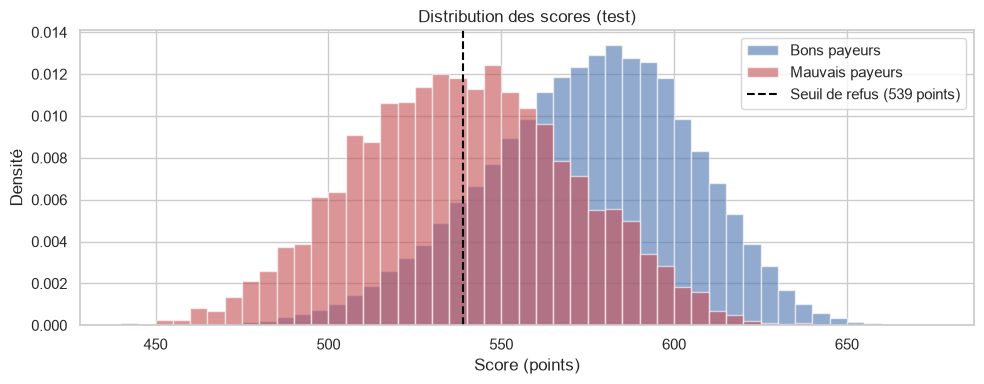

In [8]:
scores = d.pd_to_score(pd_test)
fig, ax = plt.subplots(figsize=(10, 4))
bins = np.arange(440, 680, 5)
ax.hist(scores[y_test.values == 0], bins=bins, alpha=0.6, density=True, color="#4C72B0", label="Bons payeurs")
ax.hist(scores[y_test.values == 1], bins=bins, alpha=0.6, density=True, color="#C44E52", label="Mauvais payeurs")
ax.axvline(d.pd_to_score(threshold), color="black", ls="--", label=f"Seuil de refus ({d.pd_to_score(threshold):.0f} points)")
ax.set_xlabel("Score (points)"); ax.set_ylabel("Densité")
ax.set_title("Distribution des scores (test)"); ax.legend()
plt.tight_layout(); plt.savefig(FIGURES / "06_scores.png", dpi=120); plt.show()

## 4. Les classes de risque A à E

Pour la communication interne (conseillers, comité de crédit, reporting), on regroupe les clients en **5 classes**.
La classe **E** correspond aux demandes refusées.

In [9]:
grades = d.risk_grades()
grade = d.risk_grade(pd_test)
summary = pd.DataFrame({
    "part_clients": pd.Series(grade).value_counts(normalize=True).sort_index(),
    "PD_moyenne_predite": pd.Series(pd_test).groupby(grade).mean(),
    "taux_defaut_observe": pd.Series(y_test.values).groupby(grade).mean(),
})
summary = grades.set_index("classe")[["libelle", "score_min", "score_max"]].join(summary)
summary.style.format({
    "score_min": "{:.0f}", "score_max": "{:.0f}", "part_clients": "{:.1%}",
    "PD_moyenne_predite": "{:.1%}", "taux_defaut_observe": "{:.1%}",
})

,libelle,score_min,score_max,part_clients,PD_moyenne_predite,taux_defaut_observe
classe,,,,,,
A,Risque très faible,599,inf,19.7%,1.3%,1.1%
B,Risque faible,572,599,32.9%,3.3%,3.2%
C,Risque modéré,551,572,22.8%,7.1%,7.2%
D,"Risque élevé, accepté",539,551,8.8%,11.9%,12.5%
E,"Risque trop élevé, refusé",-inf,539,15.7%,25.6%,25.8%


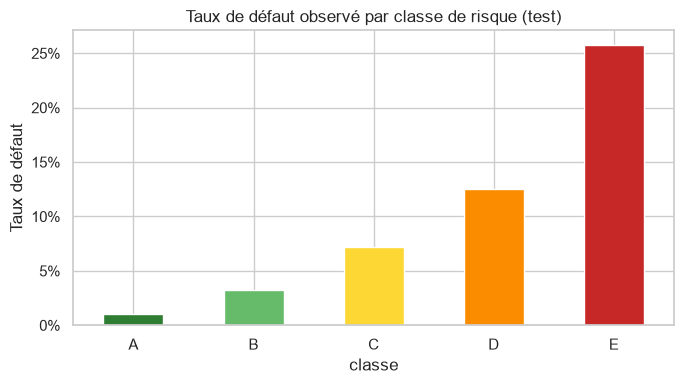

In [10]:
ax = summary["taux_defaut_observe"].plot.bar(color=["#2E7D32", "#66BB6A", "#FDD835", "#FB8C00", "#C62828"], rot=0, figsize=(7, 4))
ax.set_title("Taux de défaut observé par classe de risque (test)")
ax.set_ylabel("Taux de défaut"); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.tight_layout(); plt.savefig(FIGURES / "06_classes.png", dpi=120); plt.show()

Le taux de défaut **augmente nettement** de A à E, et le défaut observé correspond à la PD prédite dans chaque classe.

## 5. La grille de points de la scorecard

C'est l'outil historique des banques : **chaque caractéristique du client rapporte des points**, et le score est la
**somme** des points. Un analyste peut le calculer à la main et expliquer chaque point au client.

On l'obtient à partir de la scorecard (notebook 03) : pour chaque classe de chaque variable,
points = constante − facteur × coefficient × WoE.

In [11]:
points = d.scorecard_points(scorecard)
print(f"{points['variable'].nunique()} variables, {len(points)} lignes dans la grille")
points[points["variable"].isin(["EXT_SOURCE_3", "INST_LATE_RATIO_LAST_YEAR"])].style.format({
    "part_clients": "{:.1%}", "taux_defaut": "{:.1%}", "points": "{:.0f}",
}).hide(axis="index")

19 variables, 163 lignes dans la grille


variable,classe,part_clients,taux_defaut,points
EXT_SOURCE_3,"(-inf, 0.18)",5.1%,22.1%,8
EXT_SOURCE_3,"[0.18, 0.32)",9.7%,14.1%,18
EXT_SOURCE_3,"[0.32, 0.37)",5.6%,9.9%,25
EXT_SOURCE_3,"[0.37, 0.44)",6.8%,8.9%,28
EXT_SOURCE_3,"[0.44, 0.50)",8.4%,7.3%,31
EXT_SOURCE_3,"[0.50, 0.57)",9.1%,5.9%,36
EXT_SOURCE_3,"[0.57, 0.62)",8.2%,5.1%,38
EXT_SOURCE_3,"[0.62, 0.67)",7.4%,4.3%,42
EXT_SOURCE_3,"[0.67, 0.70)",5.3%,4.1%,42
EXT_SOURCE_3,"[0.70, 0.78)",9.5%,3.4%,46


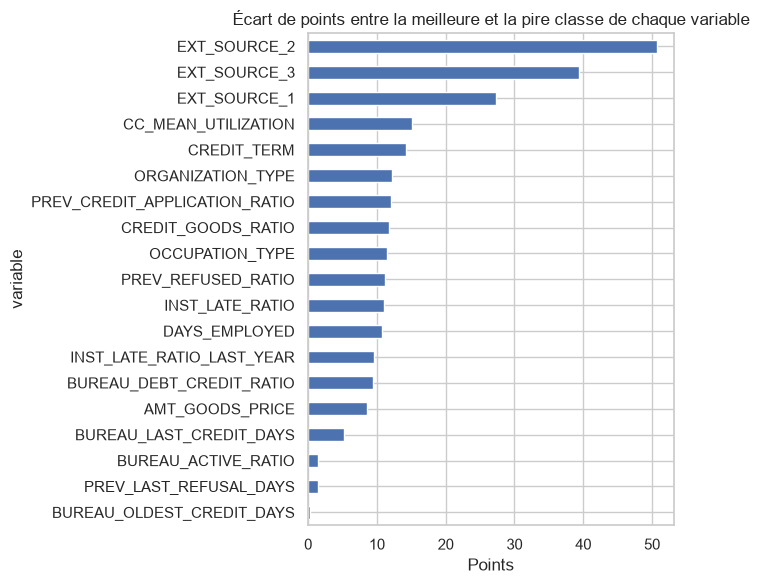

In [12]:
spread = points.groupby("variable")["points"].agg(lambda p: p.max() - p.min()).sort_values()
ax = spread.plot.barh(color="#4C72B0", figsize=(7, 6))
ax.set_title("Écart de points entre la meilleure et la pire classe de chaque variable")
ax.set_xlabel("Points")
plt.tight_layout(); plt.savefig(FIGURES / "06_grille_ecarts.png", dpi=120); plt.show()

Plus l'écart est grand, plus la variable peut faire **basculer** une décision. Les scores externes dominent,
suivis par le type d'organisation, le métier, la part financée et les variables d'historique construites en SQL.

In [13]:
# Vérification : la somme des points redonne exactement le score calculé à partir de la PD
s_points = d.scorecard_score(scorecard, X_test)
s_pd = d.pd_to_score(scorecard.predict_proba(X_test))
print(f"Écart maximal entre les deux calculs : {np.abs(s_points - s_pd).max():.1e} point")

Écart maximal entre les deux calculs : 1.1e-13 point


### Exemple : le score d'un client, ligne par ligne

In [14]:
client = X_test.iloc[[0]]
woe = scorecard.binning.transform(client, metric="woe")[scorecard.variables].iloc[0]
coefs = dict(zip(scorecard.variables, scorecard.model.coef_[0]))
base = (d.OFFSET - d.FACTOR * scorecard.model.intercept_[0]) / len(scorecard.variables)
detail = pd.DataFrame({
    "valeur": [client[v].iloc[0] for v in scorecard.variables],
    "points": [base - d.FACTOR * coefs[v] * woe[v] for v in scorecard.variables],
}, index=scorecard.variables)
total = detail["points"].sum()
pd_client = scorecard.predict_proba(client)[0]
print(f"Score total : {total:.0f} points · PD {pd_client:.1%} · classe {d.risk_grade([pd_client])[0]} · "
      f"décision : {'ACCEPTÉ' if pd_client < threshold else 'REFUSÉ'}")
detail.style.format({"points": "{:.0f}"}, na_rep="manquant")

Score total : 594 points · PD 2.4% · classe B · décision : ACCEPTÉ


,valeur,points
EXT_SOURCE_3,0.621226,38
EXT_SOURCE_2,0.571475,34
EXT_SOURCE_1,0.706058,45
DAYS_EMPLOYED,-10780.000000,36
CREDIT_TERM,0.037901,32
BUREAU_DEBT_CREDIT_RATIO,0.136456,32
AMT_GOODS_PRICE,450000.000000,25
BUREAU_ACTIVE_RATIO,0.166667,30
BUREAU_LAST_CREDIT_DAYS,-465.000000,31
OCCUPATION_TYPE,Laborers,25


## 6. Conclusions

| Question | Réponse |
|---|---|
| Quand refuser ? | Si la PD dépasse **14,3 %** (score < 539 points), avec une marge de 10 % et une LGD de 60 % |
| Combien la banque y gagne ? | Environ **+22 %** de gain par rapport à « tout accepter », en écartant la moitié des mauvais payeurs pour ~13 % des bons |
| Comment communiquer ? | Un **score** (600 = PD ≈ 2 %), **5 classes** de A à E, et une **grille de points** explicable ligne par ligne |

**Prochaine étape :** rendre le modèle utilisable par d'autres applications → **API FastAPI**, **Docker**, démo **Streamlit**
et intégration continue.